In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving gtex_integrin_7_organs.xlsx to gtex_integrin_7_organs.xlsx


In [4]:
import io

filename = list(uploaded.keys())[0]
df = pd.read_excel(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Dataset shape: (1987, 29)


,Unnamed: 0,primary_site,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE,ITGA2,ITGB3,...,ITGA6,ITGA2B,ITGB1,ITGAL,ITGA9,ITGB5,ITGA8,ITGA4,ITGA1,ITGA11
0,GTEX-13QIC-0011-R1a-SM-5O9CJ,Brain,0.5763,-6.5064,2.2573,0.7832,1.0363,4.6035,2.5731,-2.8262,...,2.8562,1.3846,5.8430,1.1316,-0.7108,3.5387,-0.0725,-0.4521,0.2029,-2.8262
1,GTEX-1399S-1726-SM-5L3DI,Lung,4.9137,-3.6259,4.7307,7.1584,1.7702,4.9556,1.9149,2.6067,...,4.2412,4.1211,7.7256,4.4900,2.9281,6.1483,5.1867,2.6185,4.7856,-0.0277
2,GTEX-PWCY-1326-SM-48TCU,Ovary,2.3953,-5.0116,1.4547,4.2593,-0.7346,4.4149,0.2642,1.5216,...,3.6816,1.5465,7.2964,-0.9406,2.7742,5.0414,2.0325,0.7579,2.2573,1.2516
3,GTEX-QXCU-0626-SM-2TC69,Lung,4.0541,-2.3147,4.5053,7.5651,4.1788,4.1772,5.3695,1.8444,...,4.9631,1.9149,7.9947,3.3911,2.8462,6.7683,4.1636,2.7951,5.3284,1.2147
4,GTEX-ZA64-1526-SM-5CVMD,Breast,2.0569,-2.4659,3.3993,3.1311,3.0074,4.4977,-1.7809,2.7139,...,4.7340,0.6332,7.3496,-0.9406,2.5338,6.5696,1.7229,-0.6416,3.1195,1.1050


Columns: ['Unnamed: 0', 'primary_site', 'ITGA10', 'ITGAD', 'ITGAM', 'ITGA3', 'ITGBL1', 'ITGAE', 'ITGA2', 'ITGB3', 'ITGA7', 'ITGB8', 'ITGAX', 'ITGAV', 'ITGB6', 'ITGB7', 'ITGA5', 'ITGB4', 'ITGB2', 'ITGA6', 'ITGA2B', 'ITGB1', 'ITGAL', 'ITGA9', 'ITGB5', 'ITGA8', 'ITGA4', 'ITGA1', 'ITGA11']


In [5]:
lung_breast = df[df["primary_site"].isin(["Lung", "Breast"])].copy()

print("Number of samples:")
print(lung_breast["primary_site"].value_counts())

display(lung_breast.head())

Number of samples:
primary_site
Lung      288
Breast    179
Name: count, dtype: int64


,Unnamed: 0,primary_site,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE,ITGA2,ITGB3,...,ITGA6,ITGA2B,ITGB1,ITGAL,ITGA9,ITGB5,ITGA8,ITGA4,ITGA1,ITGA11
1,GTEX-1399S-1726-SM-5L3DI,Lung,4.9137,-3.6259,4.7307,7.1584,1.7702,4.9556,1.9149,2.6067,...,4.2412,4.1211,7.7256,4.4900,2.9281,6.1483,5.1867,2.6185,4.7856,-0.0277
3,GTEX-QXCU-0626-SM-2TC69,Lung,4.0541,-2.3147,4.5053,7.5651,4.1788,4.1772,5.3695,1.8444,...,4.9631,1.9149,7.9947,3.3911,2.8462,6.7683,4.1636,2.7951,5.3284,1.2147
4,GTEX-ZA64-1526-SM-5CVMD,Breast,2.0569,-2.4659,3.3993,3.1311,3.0074,4.4977,-1.7809,2.7139,...,4.7340,0.6332,7.3496,-0.9406,2.5338,6.5696,1.7229,-0.6416,3.1195,1.1050
5,GTEX-11EI6-0826-SM-5985V,Lung,6.0732,-2.4659,3.9901,7.3945,4.7688,5.1157,4.3356,2.3366,...,3.7378,4.7247,7.5016,5.1396,2.5036,6.5443,4.6531,3.8136,5.8679,0.7407
6,GTEX-S341-0326-SM-2XCAU,Lung,4.2510,-5.0116,3.3076,6.1715,3.1129,5.2954,2.2960,1.1184,...,4.7104,2.7530,7.5022,4.0730,2.6325,6.0483,5.0562,2.6962,5.1611,0.9343


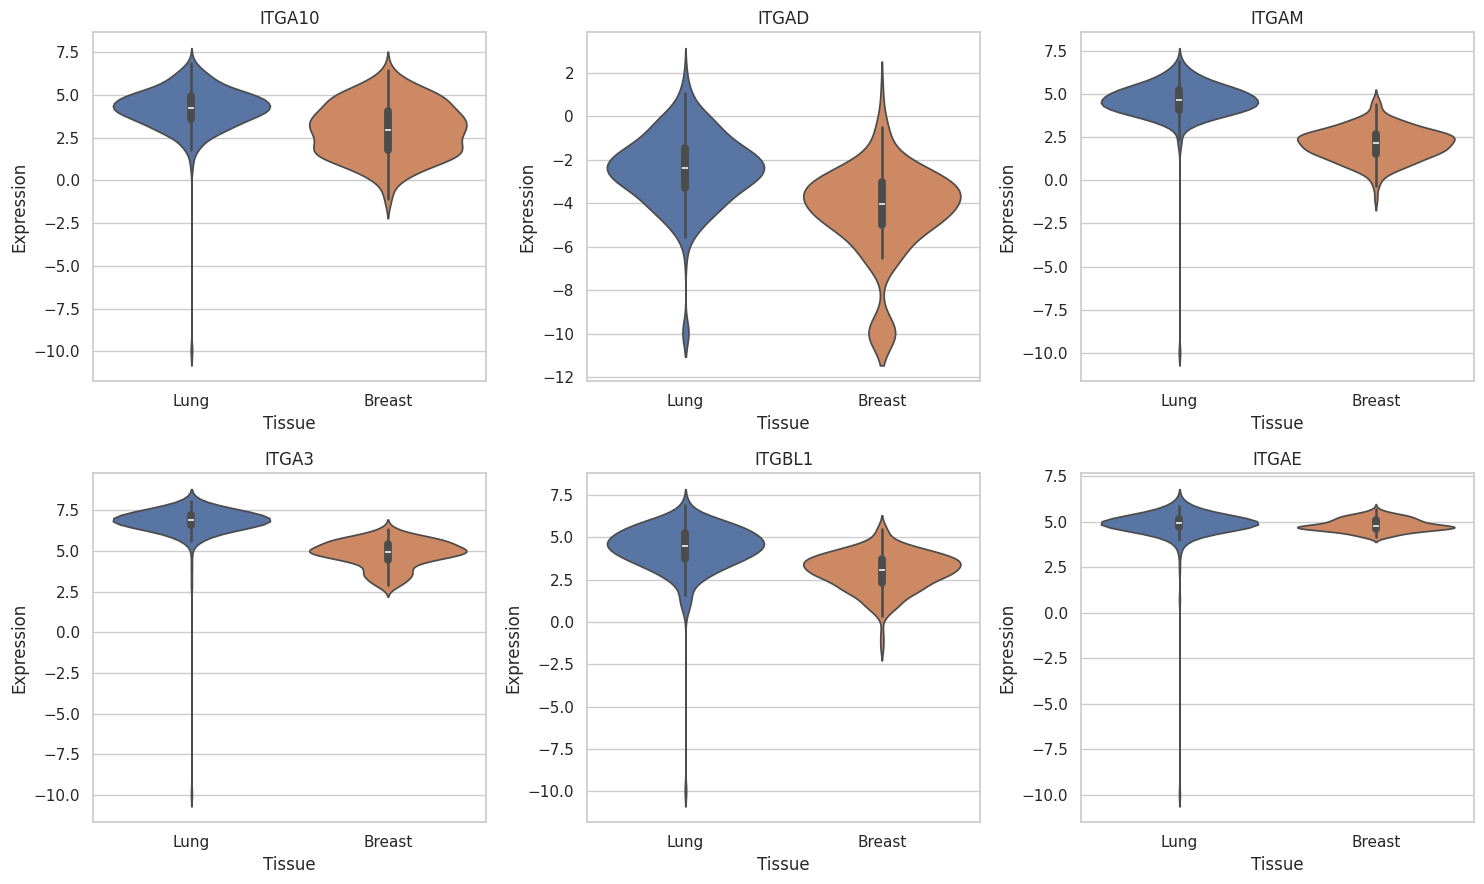

In [6]:
genes = ["ITGA10", "ITGAD", "ITGAM", "ITGA3", "ITGBL1", "ITGAE"]

plt.figure(figsize=(15, 9))

for i, gene in enumerate(genes):
    plt.subplot(2, 3, i + 1)
    sns.violinplot(
        data=lung_breast,
        x="primary_site",
        y=gene,
        hue="primary_site",
        legend=False
    )
    plt.title(gene)
    plt.xlabel("Tissue")
    plt.ylabel("Expression")

plt.tight_layout()
plt.show()

In [8]:
# Compare average gene expression in Lung and Breast

gene_means = lung_breast.groupby("primary_site")[genes].mean()

display(gene_means)

print("\nDifference in average expression:")
differences = (gene_means.loc["Lung"] - gene_means.loc["Breast"]).abs()
print(differences.sort_values(ascending=False))

,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE
primary_site,,,,,,
Breast,2.952141,-4.377718,2.093066,4.817402,2.998847,4.826808
Lung,4.199649,-2.469141,4.607177,6.793342,4.371885,4.850309



Difference in average expression:
ITGAM     2.514111
ITGA3     1.975940
ITGAD     1.908577
ITGBL1    1.373038
ITGA10    1.247508
ITGAE     0.023501
dtype: float64


Strong Predictor: ITGAM
Accuracy: 0.9574
AUC Score: 0.9794


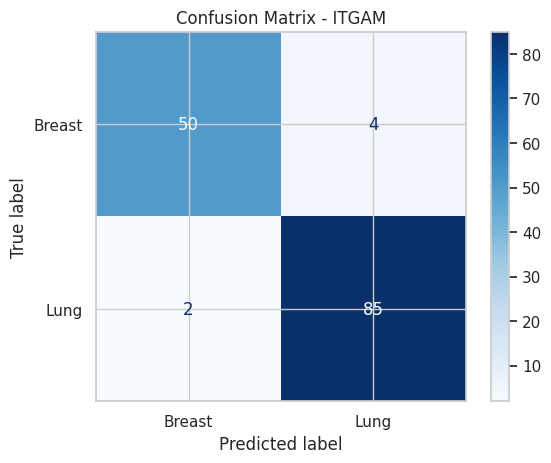

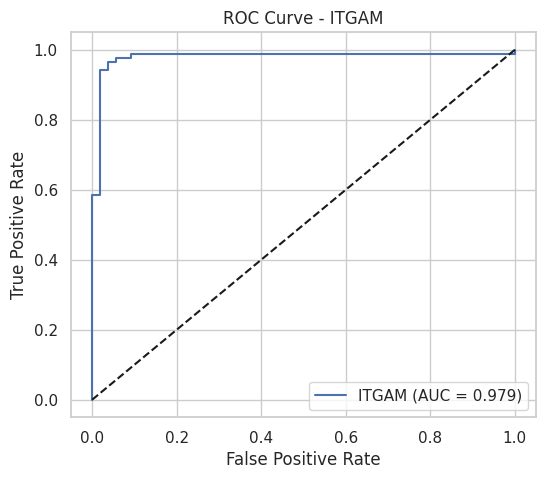

In [9]:
# Part 2: Logistic Regression with a strong predictor (ITGAM)

X = lung_breast[["ITGAM"]]
y = (lung_breast["primary_site"] == "Lung").astype(int)

# 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train logistic regression model
model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate accuracy and AUC
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("Strong Predictor: ITGAM")
print("Accuracy:", round(accuracy, 4))
print("AUC Score:", round(auc, 4))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Breast", "Lung"],
    cmap="Blues"
)
plt.title("Confusion Matrix - ITGAM")
plt.show()

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ITGAM (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - ITGAM")
plt.legend()
plt.show()

ITGAM performed very well at distinguishing Lung and Breast tissues. The logistic regression model achieved an accuracy of 95.74% and an AUC score of 0.9794. The confusion matrix showed that only 6 out of 141 samples were incorrectly classified. This supports my initial prediction that ITGAM would be a strong predictor based on the differences in gene expression between the two tissues.

Weak Predictor: ITGAE
Accuracy: 0.6099
AUC Score: 0.578


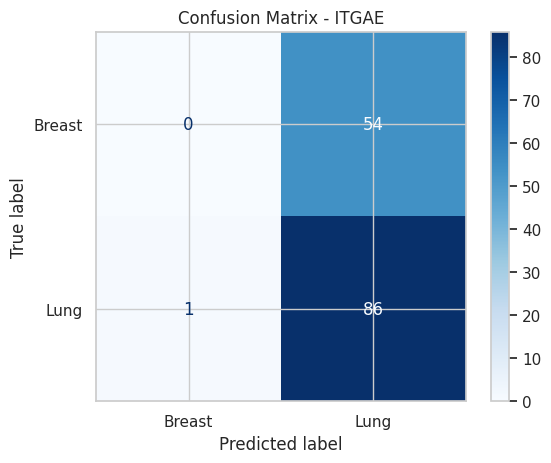

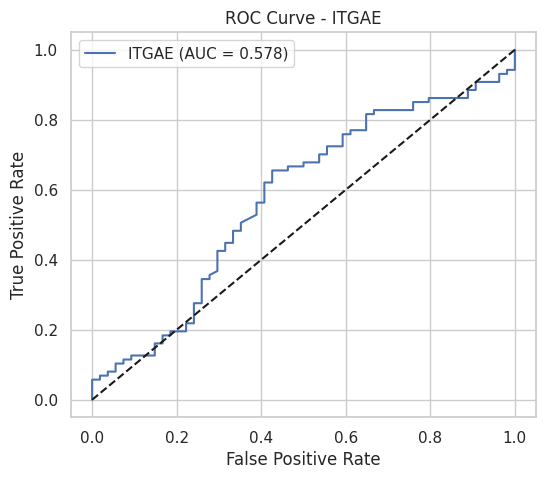

In [10]:
# Part 3: Logistic Regression with weak predictor (ITGAE)

X_weak = lung_breast[["ITGAE"]]

X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_weak, y, test_size=0.3, random_state=42, stratify=y
)

weak_model = make_pipeline(StandardScaler(), LogisticRegression())
weak_model.fit(X_train_w, y_train_w)

y_pred_w = weak_model.predict(X_test_w)
y_prob_w = weak_model.predict_proba(X_test_w)[:, 1]

accuracy_w = accuracy_score(y_test_w, y_pred_w)
auc_w = roc_auc_score(y_test_w, y_prob_w)

print("Weak Predictor: ITGAE")
print("Accuracy:", round(accuracy_w, 4))
print("AUC Score:", round(auc_w, 4))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_w, y_pred_w,
    display_labels=["Breast", "Lung"],
    cmap="Blues"
)
plt.title("Confusion Matrix - ITGAE")
plt.show()

# ROC curve
fpr_w, tpr_w, _ = roc_curve(y_test_w, y_prob_w)

plt.figure(figsize=(6, 5))
plt.plot(fpr_w, tpr_w, label=f"ITGAE (AUC = {auc_w:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - ITGAE")
plt.legend()
plt.show()

ITGAE performed much worse than ITGAM at distinguishing Lung and Breast tissues. ITGAE achieved an accuracy of 60.99% and an AUC score of 0.578, compared to ITGAM's 95.74% accuracy and 0.9794 AUC. The confusion matrix showed that ITGAE incorrectly classified all 54 Breast samples as Lung. This suggests that ITGAE has very little predictive signal for separating these two tissues. It also demonstrates why accuracy alone can be misleading when one class has more samples than the other.

Original ITGAM Accuracy: 0.9574
New ITGAM Accuracy: 0.9716
Original ITGAM AUC: 0.9794
New ITGAM AUC: 0.9989


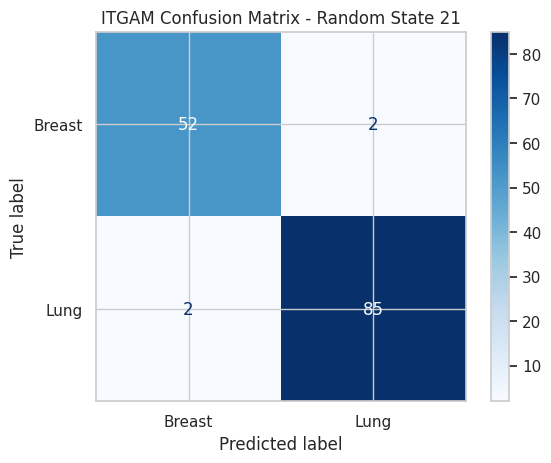

In [11]:
# Part 4: Model stability with a different random state

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y, test_size=0.3, random_state=21, stratify=y
)

model2 = make_pipeline(StandardScaler(), LogisticRegression())
model2.fit(X_train2, y_train2)

y_pred2 = model2.predict(X_test2)
y_prob2 = model2.predict_proba(X_test2)[:, 1]

accuracy2 = accuracy_score(y_test2, y_pred2)
auc2 = roc_auc_score(y_test2, y_prob2)

print("Original ITGAM Accuracy:", round(accuracy, 4))
print("New ITGAM Accuracy:", round(accuracy2, 4))

print("Original ITGAM AUC:", round(auc, 4))
print("New ITGAM AUC:", round(auc2, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test2, y_pred2,
    display_labels=["Breast", "Lung"],
    cmap="Blues"
)

plt.title("ITGAM Confusion Matrix - Random State 21")
plt.show()

Changing the random state from 42 to 21 slightly improved the ITGAM model's accuracy from 95.74% to 97.16%. The AUC score also increased from 0.9794 to 0.9989. The new confusion matrix showed only four incorrect predictions compared to six in the original model. These results suggest that ITGAM is a relatively stable predictor because both train-test splits produced high accuracy and AUC scores. However, testing additional splits would help confirm the model's reliability.

Number of organs: 7
Samples per organ:
primary_site
Brain          1152
Lung            288
Breast          179
Liver           110
Prostate        100
Ovary            88
Bone Marrow      70
Name: count, dtype: int64

Multi-class Accuracy: 0.7554


<Figure size 1000x800 with 0 Axes>

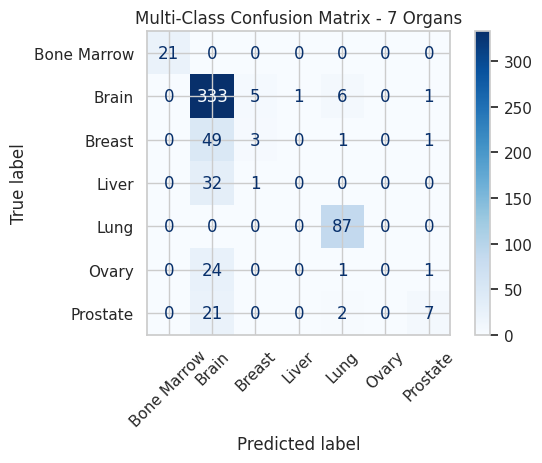

In [12]:
# Part 5: Multi-class classification using all 7 organs

features = ["ITGAM", "ITGA3"]

# Select two genes and the organ labels
multi_data = df[["primary_site"] + features].dropna()

X_multi = multi_data[features]
y_multi = multi_data["primary_site"]

print("Number of organs:", y_multi.nunique())
print("Samples per organ:")
print(y_multi.value_counts())

# Split into training and testing data
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi,
    test_size=0.3,
    random_state=42,
    stratify=y_multi
)

# Train logistic regression
multi_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

multi_model.fit(X_train_m, y_train_m)

# Predictions and accuracy
y_pred_m = multi_model.predict(X_test_m)
accuracy_m = accuracy_score(y_test_m, y_pred_m)

print("\nMulti-class Accuracy:", round(accuracy_m, 4))

# Display 7 x 7 confusion matrix
plt.figure(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test_m,
    y_pred_m,
    labels=multi_model.classes_,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Multi-Class Confusion Matrix - 7 Organs")
plt.tight_layout()
plt.show()

## Final Reflection

Binary classification involves predicting between two categories, while multi-class classification involves predicting among three or more categories. In this activity, I first used logistic regression to distinguish Lung and Breast tissues, then expanded the model to classify seven organs. ITGAM was a strong predictor, achieving 95.74% accuracy and an AUC of 0.9794, while ITGAE performed much worse with 60.99% accuracy and an AUC of 0.578. Changing the random state improved ITGAM's accuracy to 97.16%, suggesting that the model performed consistently well across the two splits tested. The seven-organ model achieved 75.54% accuracy, but the confusion matrix revealed that several tissues were frequently misclassified as Brain. Some tissues may be harder to classify because they have overlapping expression patterns for the two selected genes. This demonstrates that a confusion matrix is important because overall accuracy can hide poor performance for individual classes. Finally, classification accuracy does not prove biological causation because a gene can be useful for predicting tissue type without directly causing the biological differences between tissues.
